# PCA: reconstrucción frente a poda parcial

Diez semillas, 100 pasos uniformes comunes y 10000 de continuación. Se conserva la pérdida histórica datos+PDE+IC, red 3×32, candidatos fijos (4096), ventana de 20 snapshots y selección cada 100 pasos. PCA + media al 95%, QR + log-det y 32 propuestas. El experimento cambia la actualización del lote, manteniendo 128 puntos activos.

## Protocolo

La reconstrucción PCA renueva 32 guiados + 96 Sobol. Ambas variantes parciales comparten el lote PCA de la primera selección y entrenan 100 pasos antes de la primera poda. Después proponen 32 puntos disjuntos del lote activo, mediante PCA o Sobol. Para PCA se ajusta la base sobre la historia completa y se restringe el diseño QR/log-det a candidatos elegibles: no se vuelve a ajustar PCA tras excluir activos.

Se retiran los 32 puntos con mayor log2(|r anterior|/|r actual|), con piso 1e-12. Si alguno de esos 32 grados es negativo, se cancela la sustitución completa. Si se acepta, sobreviven 96 puntos. Se recalcula el residuo basal sobre las coordenadas actualizadas, incluidos los insertados. Los controles Sobol parcial y completo tienen historias iniciales de puntos distintas; la comparación directa de propuestas PCA/Sobol parciales sí comparte el lote inicial.

Esta prueba conserva la ampliación a 32 puntos: todavía no estudia seleccionar directamente k pivotes ni renovar candidatos. La exclusión de candidatos activos es necesaria para garantizar 32 puntos realmente nuevos. Se registran las sustituciones canceladas. No se afirma que esto sea una reproducción completa de QR-DEIM.

## Resultados terminales

| Método | RMSE prueba ± DE | Residuo RMS | RMSE IC |
|---|---:|---:|---:|
| PCA: reconstrucción | 0.08320 ± 0.01151 | 0.09586 | 0.11276 |
| PCA: poda parcial | 0.11910 ± 0.02243 | 0.11090 | 0.15843 |
| Sobol: poda parcial | 0.06076 ± 0.01712 | 0.82891 | 0.05107 |
| Sobol: remuestreo | 0.05722 ± 0.01961 | 0.31074 | 0.06560 |

El modelo se evalúa al presupuesto prefijado; no se elige por error de prueba. DE representa dispersión entre semillas.

**Comparación**

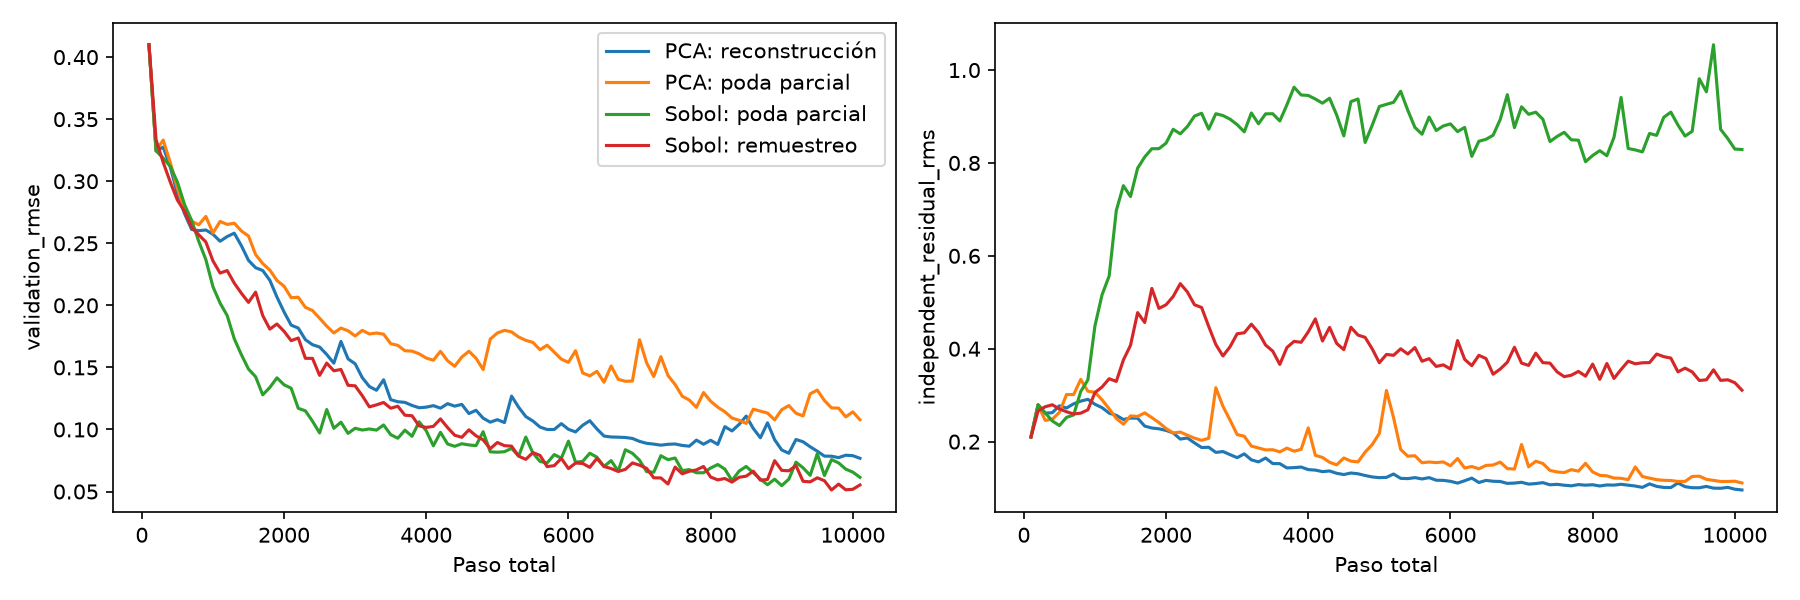

In [ ]:
from pathlib import Path
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
display(Image(filename=str(ROOT / 'pca_collocation/results/burgers/partial_update/pca95_partial_10_seeds_10k_v1/comparison.png'), format='png', embed=True))


## Comparaciones pareadas

PCA: poda parcial frente a PCA: reconstrucción: diferencia media RMSE +0.03590, mejora en 0/10 semillas.

PCA: poda parcial frente a Sobol: poda parcial: diferencia media RMSE +0.05833, mejora en 0/10 semillas.

Sobol: poda parcial frente a Sobol: remuestreo: diferencia media RMSE +0.00354, mejora en 5/10 semillas.

PCA: poda parcial: 990/990 sustituciones aceptadas. Se conservan cuatro auditorías por semilla para reconstruir la poda.

Sobol: poda parcial: 990/990 sustituciones aceptadas. Se conservan cuatro auditorías por semilla para reconstruir la poda.

## Reproducción

`python scripts/run_collocation_partial.py`; añadir `--report-only` para regenerar el reporte. Configuración: pca_collocation/configs/burgers_partial_update.json. Artefactos por método y semilla: métricas, trazas, puntos activos y auditoría de poda. Los tiempos incluyen compilación y diagnóstico. El siguiente control será comparar 32 propuestas con selección directa por rango, si estos resultados justifican continuar.